In [ ]:
!pip install ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 1.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 25.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 88.7/88.7 kB 3.9 MB/s eta 0:00:00


In [ ]:
!pip install roboflow -q
from pathlib import Path
from google.colab import userdata
from roboflow import Roboflow

Path("/content/ODOL/dataset/raw").mkdir(parents=True, exist_ok=True)

ROBOFLOW_API_KEY = userdata.get("ROBOFLOW_API_KEY")
rf = Roboflow(api_key=ROBOFLOW_API_KEY)

project = rf.workspace("sigara-hpnoo").project("truck-over-dimension-brupr")
dataset = project.version(2).download("yolov8", location="/content/ODOL/dataset/raw/truck-over-dimension")
Path(dataset.location)


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 322.4/322.4 kB 7.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 50.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 4.4 MB/s eta 0:00:00
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /content/ODOL/dataset/raw/truck-over-dimension in yolov8:: 100%|██████████| 5718/5718 [00:00<00:00, 7150.62it/s]


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


PosixPath('/content/ODOL/dataset/raw/truck-over-dimension')

In [ ]:
#import libraries and make folder

from pathlib import Path
import cv2
import numpy as np

from ultralytics import YOLO
from tensorflow.keras.models import load_model
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from google.colab import files
from IPython.display import display, Image, Video

project_folder = Path("/content/ODOL")
models_folder = project_folder / "models"
results_folder = project_folder / "results" / "pipeline"
image_results_folder = results_folder / "images"
video_results_folder = results_folder / "videos"

models_folder.mkdir(parents=True,exist_ok=True)
image_results_folder.mkdir(parents=True,exist_ok=True)
video_results_folder.mkdir(parents=True,exist_ok=True)

models_folder

PosixPath('/content/ODOL/models')

In [ ]:
uploaded_models = files.upload()

for model_name in uploaded_models:
    Path(model_name).replace(models_folder / model_name)

models_folder

Saving best.pt to best.pt
Saving mobilenet_odol_classifier(V2).keras to mobilenet_odol_classifier(V2).keras


PosixPath('/content/ODOL/models')

In [ ]:
yolo_model = YOLO(models_folder / "best.pt")
classifier_model = load_model(models_folder / "mobilenet_odol_classifier(V2).keras")

In [ ]:
detection_threshold = 0.30
not_odol_threshold = 0.40
odol_threshold = 0.60

minimum_crop_size = 80
history_length = 5

prediction_history = {}

def process_frame(frame,tracking=False):
    output_frame = frame.copy()
    frame_width = output_frame.shape[1]

    if tracking:
        results = yolo_model.track(frame,persist=True,tracker="bytetrack.yaml",conf=detection_threshold,imgsz=640,verbose=False)
    else:
        results = yolo_model(frame,conf=detection_threshold,imgsz=640,verbose=False)

    for box in results[0].boxes:
        x1,y1,x2,y2 = box.xyxy[0].cpu().numpy().astype(int)
        detection_confidence = box.conf[0].item()

        h, w = frame.shape[:2]
        x1 = max(0, x1)
        y1 = max(0, y1)
        x2 = min(w, x2)
        y2 = min(h, y2)
        if x2 <= x1 or y2 <= y1:
            continue

        if box.id is not None:
            truck_id = int(box.id.item())
            truck_name = f"Truck {truck_id}"
        else:
            truck_id = None
            truck_name = "Truck"

        truck_crop = frame[y1:y2,x1:x2]
        crop_height,crop_width = truck_crop.shape[:2]

        if crop_width < minimum_crop_size or crop_height < minimum_crop_size:
            text = f"{truck_name} | TOO FAR | Detection {detection_confidence:.1%}"
            color = (0,165,255)

        else:
            truck_crop = cv2.cvtColor(truck_crop,cv2.COLOR_BGR2RGB)
            truck_crop = cv2.resize(truck_crop,(224,224))
            truck_crop = np.expand_dims(truck_crop,axis=0)
            truck_crop = preprocess_input(truck_crop.astype(np.float32))

            prediction = classifier_model.predict(truck_crop,verbose=0)[0][0].item()

            if truck_id is not None:
                if truck_id not in prediction_history:
                    prediction_history[truck_id] = []

                prediction_history[truck_id].append(prediction)
                prediction_history[truck_id] = prediction_history[truck_id][-history_length:]

                average_prediction = np.mean(prediction_history[truck_id])
            else:
                average_prediction = prediction

            if average_prediction >= odol_threshold:
                text = f"{truck_name} | ODOL {average_prediction:.1%} | Detection {detection_confidence:.1%}"
                color = (0,0,255)

            elif average_prediction <= not_odol_threshold:
                confidence = 1 - average_prediction
                text = f"{truck_name} | NOT ODOL {confidence:.1%} | Detection {detection_confidence:.1%}"
                color = (0,255,0)

            else:
                text = f"{truck_name} | UNCERTAIN | ODOL score {average_prediction:.1%}"
                color = (0,255,255)

        text_width = cv2.getTextSize(text,cv2.FONT_HERSHEY_SIMPLEX,0.7,2)[0][0]

        text_x = max(0,min(x1,frame_width - text_width - 10))
        text_y = max(y1 - 10,30)

        cv2.rectangle(output_frame,(x1,y1),(x2,y2),color,3)
        cv2.putText(output_frame,text,(text_x,text_y),cv2.FONT_HERSHEY_SIMPLEX,0.7,color,2)

    return output_frame

In [ ]:
from sklearn.model_selection import train_test_split

raw_base = Path("/content/ODOL/dataset/raw/truck-over-dimension")

# rebuild pairs like mobilenet cells 3-4
pairs = []
for s in ["train", "valid", "test"]:
    img_f = raw_base / s / "images"
    lbl_f = raw_base / s / "labels"
    for img_file in sorted(img_f.glob("*.jpg")):
        lbl_file = lbl_f / f"{img_file.stem}.txt"
        if lbl_file.exists():
            pairs.append((img_file, lbl_file))

groups = {}
for img_file, lbl_file in pairs:
    g = img_file.stem.split(".rf.")[0]
    groups.setdefault(g, []).append((img_file, lbl_file))

group_names = sorted(groups.keys())
group_labels = []
for g in group_names:
    has_odol = False
    for img_file, lbl_file in groups[g]:
        for line in lbl_file.read_text().splitlines():
            if int(line.split()[0]) == 1:
                has_odol = True
                break
        if has_odol:
            break
    group_labels.append(1 if has_odol else 0)

train_g, temp_g, _, temp_l = train_test_split(
    group_names, group_labels, test_size=0.30, stratify=group_labels, random_state=42
)
valid_g, test_g = train_test_split(
    temp_g, test_size=0.5, stratify=temp_l, random_state=42
)
test_set = set(test_g)
print("new test groups:", len(test_set))

# pick 1 original per group (no .rf. = original)
test_files = []
for g in sorted(test_set):
    items = groups[g]
    orig = [x for x in items if ".rf." not in x[0].stem]
    test_files.append((orig[0] if orig else items[0]))

total = detected = missed = correct = uncertain = 0
for img_file, lbl_file in sorted(test_files):
    gt = 0
    for line in lbl_file.read_text().splitlines():
        if int(line.split()[0]) == 1:
            gt = 1
            break
    total += 1
    frame = cv2.imread(str(img_file))
    h, w = frame.shape[:2]
    results = yolo_model(frame, conf=detection_threshold, imgsz=640, verbose=False)
    if len(results[0].boxes) == 0:
        missed += 1
        continue
    boxes = results[0].boxes.xyxy.cpu().numpy().astype(int)
    x1, y1, x2, y2 = max(boxes, key=lambda b: (b[2]-b[0])*(b[3]-b[1]))
    x1, y1 = max(0, x1), max(0, y1)
    x2, y2 = min(w, x2), min(h, y2)
    if x2 <= x1 or y2 <= y1 or (x2-x1) < minimum_crop_size or (y2-y1) < minimum_crop_size:
        missed += 1
        continue
    detected += 1
    crop = cv2.cvtColor(frame[y1:y2, x1:x2], cv2.COLOR_BGR2RGB)
    crop = cv2.resize(crop, (224, 224))
    crop = preprocess_input(np.expand_dims(crop.astype(np.float32), axis=0))
    pred = classifier_model.predict(crop, verbose=0)[0][0].item()
    if pred >= odol_threshold:
        pred_label, is_unc = 1, False
    elif pred <= not_odol_threshold:
        pred_label, is_unc = 0, False
    else:
        uncertain += 1
        continue
    if pred_label == gt:
        correct += 1

print(f"Total full images: {total}")
print(f"Detected: {detected} / Missed+too small: {missed}")
print(f"Uncertain: {uncertain}")
print(f"End-to-end accuracy: {correct}/{detected-uncertain} = {correct/max(1,detected-uncertain):.3f}")

new test groups: 165
Total full images: 165
Detected: 144 / Missed+too small: 21
Uncertain: 7
End-to-end accuracy: 98/137 = 0.715


In [ ]:
from pathlib import Path
print(Path("/content/ODOL/dataset/raw/truck-over-dimension/test/images").exists())

False


Saving VID_20210816_164254 22.jpg to VID_20210816_164254 22 (1).jpg


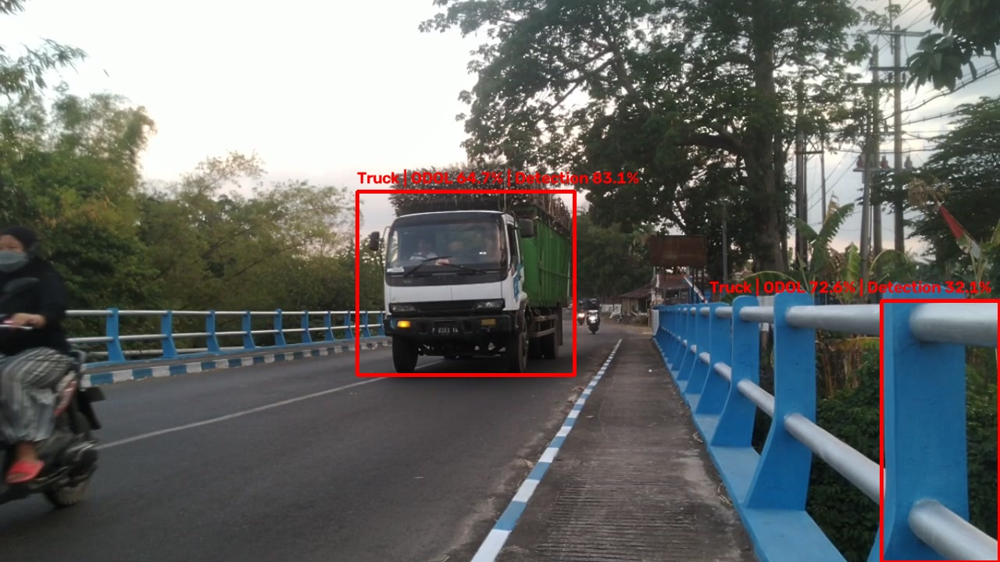

In [ ]:
uploaded_images = files.upload()

for image_name in uploaded_images:
    image = cv2.imread(image_name)
    result_image = process_frame(image)

    output_path = f"/content/ODOL/results/pipeline/images/{Path(image_name).stem}_result.jpg"

    cv2.imwrite(output_path,result_image)
    display(Image(output_path,width=900))

In [ ]:
# download the image file

files.download(output_path)

In [ ]:
uploaded_videos = files.upload()

video_name = next(iter(uploaded_videos))
output_video_path = "/content/ODOL/results/pipeline/videos/odol_result.mp4"

video = cv2.VideoCapture(video_name)

fps = video.get(cv2.CAP_PROP_FPS)
width = int(video.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(video.get(cv2.CAP_PROP_FRAME_HEIGHT))

fourcc = cv2.VideoWriter_fourcc(*"mp4v")
video_writer = cv2.VideoWriter(output_video_path,fourcc,fps,(width,height))

Saving vecteezy_traffic-situation-on-toll-roads-in-jakarta-indonesia_11735117.mp4 to vecteezy_traffic-situation-on-toll-roads-in-jakarta-indonesia_11735117.mp4


In [ ]:
# everytime u run a new video always start from here first
prediction_history.clear()

while True:
    success,frame = video.read()

    if not success:
        break

    result_frame = process_frame(frame,tracking=True)
    video_writer.write(result_frame)

video.release()
video_writer.release()

output_video_path

'/content/ODOL/results/pipeline/videos/odol_result.mp4'

In [ ]:
!ffmpeg -y -loglevel error -i "/content/ODOL/results/pipeline/videos/odol_result.mp4" -vcodec libx264 -pix_fmt yuv420p "/content/ODOL/results/pipeline/videos/odol_result_playable.mp4"

Video("/content/ODOL/results/pipeline/videos/odol_result_playable.mp4",embed=True,width=900)

In [ ]:
files.download("/content/ODOL/results/pipeline/videos/odol_result_playable.mp4")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>